# `vkspatial` Demo — SpatialPandas / cuSpatial-Style Vulkan GPU Geospatial Indexing

Demonstrates GPU WGS84 ↔ Web Mercator projections, great-circle Haversine distances, 2D Morton (Z-order) spatial partitioning via `GeoDataFrame.pack_partitions()`, zero-copy SPIR-V `point_in_polygon()`, and fast `bbox()` / `radius_query()` lookups.

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vkpandas as vpd
import vkspatial as vksp

# 1. GPU WGS84 <-> Web Mercator round-trip & Haversine distance
cities = {
    "New York": (-74.0060, 40.7128),
    "London":   (-0.1278,  51.5074),
    "Paris":    ( 2.3522,  48.8566),
    "Tokyo":    (139.6917, 35.6895),
}
lons = np.array([v[0] for v in cities.values()], dtype=np.float32)
lats = np.array([v[1] for v in cities.values()], dtype=np.float32)
mx, my = vksp.lonlat_to_mercator(lons, lats)
rlon, rlat = vksp.mercator_to_lonlat(mx, my)
print("Max projection round-trip error (deg):", float(np.max(np.abs(lons - rlon.to_numpy()))))

d_nyc_km = vksp.haversine_distance(
    np.full_like(lons, -74.0060), np.full_like(lats, 40.7128), lons, lats, unit="km"
).to_numpy()
for name, d in zip(cities.keys(), d_nyc_km):
    print(f"  NYC -> {name:8s}: {d:8.1f} km")

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Max projection round-trip error (deg): 0.0
  NYC -> New York:      0.0 km
  NYC -> London  :   5570.8 km
  NYC -> Paris   :   5837.9 km
  NYC -> Tokyo   :  10848.5 km


In [2]:
# 2. Generate 1M geospatial points around Manhattan & build 2D Morton-partitioned GeoDataFrame
rng = np.random.default_rng(7)
n = 1_000_000
pt_lons = rng.uniform(-74.03, -73.92, size=n).astype(np.float32)
pt_lats = rng.uniform( 40.69,  40.81, size=n).astype(np.float32)
px, py = vksp.lonlat_to_mercator(pt_lons, pt_lats)
df = vpd.DataFrame({
    "x": px,
    "y": py,
    "value": rng.uniform(5.0, 80.0, size=n).astype(np.float32),
})

t0 = time.perf_counter()
gdf = vksp.GeoDataFrame(df, x="x", y="y").pack_partitions(npartitions=128)
print(f"Packed {len(gdf):,} points into {len(gdf._partitions)} GPU Morton partitions in {(time.perf_counter()-t0)*1000:.1f} ms")

# Fast radius_query around Times Square (500 m)
ts_x, ts_y = vksp.lonlat_to_mercator(np.array([-73.9855], dtype=np.float32), np.array([40.7580], dtype=np.float32))
t0 = time.perf_counter()
near_ts = gdf.radius_query(float(ts_x.to_numpy()[0]), float(ts_y.to_numpy()[0]), radius=500.0)
print(f"radius_query(500m around Times Square): {len(near_ts):,} hits in {(time.perf_counter()-t0)*1000:.1f} ms")

# Zero-copy GPU point_in_polygon (Central Park polygon)
cp_ring = [(-73.9819, 40.7681), (-73.9580, 40.7644), (-73.9493, 40.7969), (-73.9730, 40.8005)]
cpx, cpy = vksp.lonlat_to_mercator(
    np.array([p[0] for p in cp_ring], dtype=np.float32),
    np.array([p[1] for p in cp_ring], dtype=np.float32),
)
cp_poly = np.column_stack([cpx.to_numpy(), cpy.to_numpy()]).astype(np.float32)
t0 = time.perf_counter()
in_park = gdf.within_polygon(cp_poly)
print(f"within_polygon(Central Park):           {len(in_park):,} hits in {(time.perf_counter()-t0)*1000:.1f} ms")

Packed 1,000,000 points into 128 GPU Morton partitions in 534.0 ms
radius_query(500m around Times Square): 3,659 hits in 26.7 ms
within_polygon(Central Park):           60,940 hits in 79.9 ms


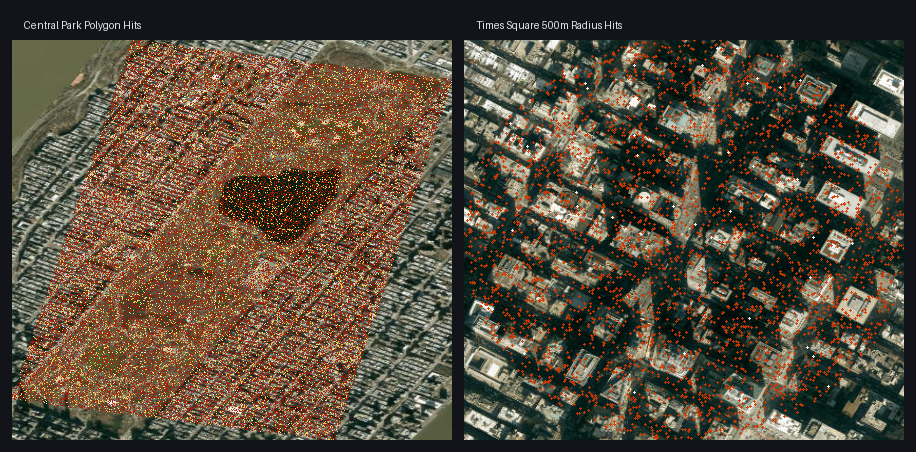

In [3]:
import vkplot.vkpandas  # noqa: F401

(
    vksp.GeoDataFrame(in_park, x="x", y="y").vkplot.points(tiles="esri", width=440, height=400, title="Central Park Polygon Hits")
    + vksp.GeoDataFrame(near_ts, x="x", y="y").vkplot.points(tiles="esri", width=440, height=400, title="Times Square 500m Radius Hits")
).cols(2)